In [12]:
%pip install -q confluent-kafka certifi pandas scikit-learn joblib matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Workshop 3: Pipeline ETL con Apache Kafka y Machine Learning (World Happiness Report)

## 1. Extracción de eventos desde Kafka
El punto de partida de este pipeline consiste en leer los registros históricos de los cinco reportes anuales (2015 a 2019) que ya fueron publicados en el tópico `etl.records`. Para conectarme al broker en Azure de forma cifrada, configuré el consumidor de `confluent-kafka` con autenticación `SASL_SSL` (`SCRAM-SHA-512`) apoyándome en los certificados raíz de `certifi`.

Como necesito reconstruir todo el historial desde cero sin perder mensajes si vuelvo a correr la celda en Colab, dejé el `group.id` en `earliest` y desactivé el *auto-commit* de offsets. Además, para evitar que el ciclo `poll()` se quede escuchando indefinidamente una vez terminados los datos disponibles, agregué un contador de intentos vacíos consecutivos (`max_empty_polls`): cuando el consumidor deja de recibir eventos tras alcanzar el final de las particiones, cierra la conexión automáticamente.

Al inspeccionar el primer mensaje, noté que los datos no vienen planos, sino envueltos en dos bloques: `metadata` (con el nombre del archivo original y el año) y `data` (con las métricas de cada país). Por eso, antes de pasar al análisis exploratorio, desempaqueté ambos diccionarios para armar un único `DataFrame` tabular (`df_flat`) con los **782 registros** extraídos[cite: 8].

In [4]:
import json
import time
import certifi
import pandas as pd
from typing import List, Dict, Any, Tuple
from confluent_kafka import Consumer, KafkaError, KafkaException

KAFKA_CONFIG = {
    "bootstrap.servers": "kafka-classroom-2026.westus.cloudapp.azure.com:9092",
    "security.protocol": "SASL_SSL",
    "sasl.mechanism": "SCRAM-SHA-512",
    "sasl.username": "classroom-students",
    "sasl.password": "06058462dc7f13b89eb5ace927b989984e77536417605379", 
    "ssl.ca.location": certifi.where(),
    "group.id": "leidy-johana-alomia-zapata",
    "auto.offset.reset": "earliest",
    "enable.auto.commit": False,
}

TOPIC_NAME = "etl.records"

def consume_all_records(
    config: Dict[str, Any],
    topic: str,
    poll_timeout: float = 2.0,
    max_empty_polls: int = 4,
) -> Tuple[List[Dict[str, Any]], List[Dict[str, Any]]]:
    """
    Consume todos los mensajes disponibles en un tópico de Kafka hasta alcanzar el final (EOF)
    sin quedarse en un bucle infinito.

    Args:
        config: Diccionario de configuración para confluent_kafka.Consumer.
        topic: Nombre del tópico a suscribir.
        poll_timeout: Tiempo máximo (en segundos) de espera por mensaje en cada poll().
        max_empty_polls: Número de polls vacíos consecutivos tras recibir datos para asumir EOF.

    Returns:
        Tuple con:
          - state_records: Lista de diccionarios con los payloads deserializados.
          - kafka_metadata: Lista de diccionarios con metadatos de broker por mensaje.
    """
    consumer = Consumer(config)
    consumer.subscribe([topic])

    state_records: List[Dict[str, Any]] = []
    kafka_metadata: List[Dict[str, Any]] = []

    empty_polls = 0
    messages_started = False
    deserialization_errors = 0

    print(f"Conectando al clúster y suscribiendo al tópico '{topic}'...")
    start_time = time.time()

    try:
        while True:
            msg = consumer.poll(timeout=poll_timeout)

            if msg is None:
                empty_polls += 1
                threshold = max_empty_polls if messages_started else max_empty_polls * 2
                print(f"  [Poll vacío {empty_polls}/{threshold}] Esperando eventos...")
                if empty_polls >= threshold:
                    print("Fin del stream alcanzado (High Watermark). Deteniendo consumidor.")
                    break
                continue

            if msg.error():
                if msg.error().code() == KafkaError._PARTITION_EOF:
                    continue
                else:
                    raise KafkaException(msg.error())

            empty_polls = 0
            messages_started = True

            raw_key = msg.key().decode("utf-8") if msg.key() is not None else None
            meta = {
                "topic": msg.topic(),
                "partition": msg.partition(),
                "offset": msg.offset(),
                "key": raw_key,
                "timestamp_ms": msg.timestamp()[1],
            }
            kafka_metadata.append(meta)

            try:
                raw_value = msg.value().decode("utf-8")
                payload = json.loads(raw_value)

                if isinstance(payload, str):
                    payload = json.loads(payload)

                if isinstance(payload, dict):
                    state_records.append(payload)
                else:
                    print(f"Registro inesperado en offset {meta['offset']}: {type(payload)}")

            except (json.JSONDecodeError, UnicodeDecodeError) as e:
                deserialization_errors += 1
                print(f"Error deserializando mensaje en partición {meta['partition']}, offset {meta['offset']}: {e}")

    finally:

        consumer.close()
        elapsed = time.time() - start_time
        print(f"\nConexión cerrada en {elapsed:.2f}s | Registros extraídos: {len(state_records)} | Errores JSON: {deserialization_errors}")

    return state_records, kafka_metadata

state, metadata = consume_all_records(KAFKA_CONFIG, TOPIC_NAME)

if state:
    print("INSPECCIÓN DEL PRIMER MENSAJE EXTRAÍDO")
   
    print("Metadatos de Kafka:")
    print(json.dumps(metadata[0], indent=2, ensure_ascii=False))

    print("\nPayload JSON Deserializado:")
    print(json.dumps(state[0], indent=2, ensure_ascii=False))

    df_raw = pd.DataFrame(state)

    print("RESUMEN DEL DATAFRAME EN MEMORIA (df_raw)")
    
    print(f"Dimensiones (filas, columnas): {df_raw.shape}")
    print("\nTipos de datos y conteo de nulos por columna:")
    print(df_raw.info())

    print("\nPrimeras 5 filas:")
    display(df_raw.head())
else:
    print("No se extrajeron registros. Verifica la contraseña o que el tópico tenga mensajes.")

Conectando al clúster y suscribiendo al tópico 'etl.records'...
  [Poll vacío 1/8] Esperando eventos...
  [Poll vacío 2/8] Esperando eventos...
  [Poll vacío 1/4] Esperando eventos...
  [Poll vacío 2/4] Esperando eventos...
  [Poll vacío 3/4] Esperando eventos...
  [Poll vacío 4/4] Esperando eventos...
Fin del stream alcanzado (High Watermark). Deteniendo consumidor.

Conexión cerrada en 13.61s | Registros extraídos: 782 | Errores JSON: 0
INSPECCIÓN DEL PRIMER MENSAJE EXTRAÍDO
Metadatos de Kafka:
{
  "topic": "etl.records",
  "partition": 1,
  "offset": 1,
  "key": "2015-1",
  "timestamp_ms": 1794769254623
}

Payload JSON Deserializado:
{
  "metadata": {
    "source_file": "2015.csv",
    "year": 2015,
    "record_id": "2015-1"
  },
  "data": {
    "Country": "Switzerland",
    "Region": "Western Europe",
    "Happiness Rank": 1,
    "Happiness Score": 7.587,
    "Standard Error": 0.03411,
    "Economy (GDP per Capita)": 1.39651,
    "Family": 1.34951,
    "Health (Life Expectancy)": 0

,metadata,data
0,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Switzerland', 'Region': 'Western ..."
1,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Iceland', 'Region': 'Western Euro..."
2,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Netherlands', 'Region': 'Western ..."
3,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Australia', 'Region': 'Australia ..."
4,"{'source_file': '2015.csv', 'year': 2015, 'rec...","{'Country': 'Austria', 'Region': 'Western Euro..."


## 2. Preparación de datos y exploración inicial (Data Preparation)

### Revisión por año, esquemas heterogéneos y limpieza
Al revisar el `DataFrame` aplanado, confirmé que los 782 registros se reparten de forma bastante pareja entre los cinco años (158 en 2015, 157 en 2016, 155 en 2017 y 156 tanto en 2018 como en 2019)[cite: 1]. Sin embargo, cruzar la presencia de columnas reveló un problema clásico al trabajar con series históricas: **solo una columna (`Generosity`) conservó exactamente el mismo nombre en las cinco ediciones**. Las demás cambiaron de formato o nomenclatura (por ejemplo, `Family` en 2015–2017 pasó a llamarse `Social support` en 2018–2019, y en 2017 los espacios se reemplazaron por puntos).

Para unificar la información sin perder datos, seguí estos pasos de limpieza:
* **Homologación de columnas:** Agrupé las variantes equivalentes bajo nombres estándar (`gdp_per_capita`, `social_support`, `healthy_life_expectancy`, `freedom`, `generosity`, `corruption_perception` y `happiness_score`).
* **Consistencia de texto y tipos:** Limpié espacios sobrantes en los nombres de los países, unifiqué alias históricos (como *Taiwan Province of China* con *Taiwan*) y forcé la conversión numérica de todas las métricas.
* **Tratamiento de valores faltantes:** Como la columna `Region` solo venía incluida en 2015 y 2016, armé un diccionario de referencia por país a partir de esos dos primeros años para completar la región en 2017, 2018 y 2019. Tras esto, el único valor nulo que quedó en todo el conjunto fue la percepción de corrupción de Emiratos Árabes Unidos en 2018 (`corruption_perception`)[cite: 2]. Decidí dejar ese `NaN` intacto en `df_harmonized` para que el pipeline de entrenamiento lo impute usando solo los datos de *train*, mientras que para las gráficas del EDA lo completé temporalmente con la mediana de su región.
* **Revisión de valores atípicos (Outliers):** Al aplicar el criterio de $1.5 \times \text{IQR}$, aparecieron varios valores extremos en `corruption_perception` (68 casos), `generosity` (17) y `social_support` (10)[cite: 7]. Al revisar a qué países correspondían (como Singapur o Ruanda en confianza institucional), comprobé que son mediciones reales y no errores de digitación, así que opté por conservarlos.

### Cómo integré los años y qué limitaciones tiene esta decisión
Opté por apilar los cinco años verticalmente bajo un mismo esquema (*vertical stacking*), manteniendo la columna `year` para identificar cada periodo. Elegí este camino en lugar de hacer un cruce horizontal (*inner join* por país) porque cruzar por país habría reducido la muestra a unos 140 países (descartando naciones que faltaron en algún reporte) y habría quintuplicado el número de columnas, complicando innecesariamente el entrenamiento.

Aun así, esta integración tiene dos limitaciones que vale la pena tener presentes: primero, entre 2015 y 2019 hubo ligeros ajustes metodológicos en las encuestas de *Gallup*, por lo que las escalas de variables como `Family` y `Social support` no son 100% idénticas; segundo, al tener hasta cinco observaciones de un mismo país en distintos años, una partición aleatoria estándar puede dejar años distintos de un mismo país tanto en entrenamiento como en prueba, haciendo que las métricas de validación sean un poco más optimistas de lo que serían frente a un país completamente nuevo.

In [9]:
years = sorted(df_flat["year"].dropna().unique())
cols_by_year = {}


print("INSPECCIÓN DE REGISTROS Y COLUMNAS ACTIVAS POR AÑO")

for yr in years:
    sub = df_flat[df_flat["year"] == yr]
    active_cols = {
        c for c in sub.columns
        if c not in ["year", "source_file"] and sub[c].notna().any()
    }
    cols_by_year[yr] = active_cols
    print(f"• Año {yr}: {len(sub)} registros | {len(active_cols)} columnas activas -> {sorted(active_cols)}")

common_cols = set.intersection(*cols_by_year.values())
all_unique_cols = set.union(*cols_by_year.values())
non_common_cols = all_unique_cols - common_cols


print("MATRIZ DE COLUMNAS COMUNES VS. ÚNICAS / PARCIALES")
print(f"Columnas con nombre idéntico en los 5 años ({len(common_cols)}): {sorted(common_cols)}")
print(f"Columnas que varían o son exclusivas ({len(non_common_cols)}): {len(non_common_cols)}")

schema_matrix = pd.DataFrame(index=sorted(all_unique_cols))
for yr in years:
    schema_matrix[str(yr)] = [col in cols_by_year[yr] for col in schema_matrix.index]

schema_matrix["Años_Presente"] = schema_matrix.sum(axis=1)
schema_matrix["Clasificacion"] = np.where(
    schema_matrix["Años_Presente"] == len(years),
    "Común (5/5 años)",
    np.where(schema_matrix["Años_Presente"] == 1, "Única (1 año)", "Parcial (2-4 años)")
)
display(schema_matrix.sort_values(by=["Años_Presente", "Clasificacion"], ascending=[False, True]))


CANONICAL_SCHEMA_MAP = {
    "country": ["Country", "Country or region"],
    "region": ["Region"],
    "happiness_rank": ["Happiness Rank", "Happiness.Rank", "Overall rank"],
    "happiness_score": ["Happiness Score", "Happiness.Score", "Score"],
    "gdp_per_capita": ["Economy (GDP per Capita)", "Economy..GDP.per.Capita.", "GDP per capita"],
    "social_support": ["Family", "Social support"],
    "healthy_life_expectancy": ["Health (Life Expectancy)", "Health..Life.Expectancy.", "Healthy life expectancy"],
    "freedom": ["Freedom", "Freedom to make life choices"],
    "generosity": ["Generosity"],
    "corruption_perception": ["Trust (Government Corruption)", "Trust..Government.Corruption.", "Perceptions of corruption"],
}

df_clean = pd.DataFrame()
df_clean["year"] = pd.to_numeric(df_flat["year"], errors="coerce").astype(int)
df_clean["source_file"] = df_flat["source_file"].astype(str)

for canonical_col, variants in CANONICAL_SCHEMA_MAP.items():
    existing = [c for c in variants if c in df_flat.columns]
    df_clean[canonical_col] = df_flat[existing].bfill(axis=1).iloc[:, 0]


COUNTRY_ALIASES = {
    "Taiwan Province of China": "Taiwan",
    "Hong Kong S.A.R., China": "Hong Kong",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "North Macedonia": "Macedonia",
}
df_clean["country"] = df_clean["country"].astype(str).str.strip().replace(COUNTRY_ALIASES)

NUMERIC_COLS = [
    "happiness_rank", "happiness_score", "gdp_per_capita", "social_support",
    "healthy_life_expectancy", "freedom", "generosity", "corruption_perception"
]
for col in NUMERIC_COLS:
    if df_clean[col].dtype == object:
        df_clean[col] = df_clean[col].astype(str).str.replace(",", ".", regex=False)
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")


country_to_region = (
    df_clean.dropna(subset=["region"])
    .drop_duplicates(subset=["country"])
    .set_index("country")["region"]
    .to_dict()
)
df_clean["region"] = df_clean["region"].fillna(df_clean["country"].map(country_to_region)).fillna("Sub-Saharan Africa")


df_clean = df_clean.drop_duplicates(subset=["country", "year"], keep="first")


print("INDENTIFICACIÓN DE NULOS Y DIAGNÓSTICO DE OUTLIERS (1.5 * IQR)")
print("Nulos remanentes por columna (antes de ML Pipeline):")
print(df_clean.isna().sum()[df_clean.isna().sum() > 0])

df_harmonized = df_clean.copy()

df_eda = df_clean.copy()
df_eda["corruption_perception"] = df_eda["corruption_perception"].fillna(
    df_eda.groupby(["region", "year"])["corruption_perception"].transform("median")
)

outlier_rows = []
for col in ["happiness_score"] + NUMERIC_COLS[2:]:
    q1, q3 = df_eda[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df_eda[col] < low) | (df_eda[col] > high)).sum())
    outlier_rows.append({
        "Variable": col,
        "Rango_IQR_Esperado": f"[{low:.3f}, {high:.3f}]",
        "Outliers_Detectados": n_out,
        "Decision": "Conservado (caso socioeconómico real, no error de medición)"
    })
display(pd.DataFrame(outlier_rows))

INSPECCIÓN DE REGISTROS Y COLUMNAS ACTIVAS POR AÑO
• Año 2015: 158 registros | 12 columnas activas -> ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Region', 'Standard Error', 'Trust (Government Corruption)']
• Año 2016: 157 registros | 13 columnas activas -> ['Country', 'Dystopia Residual', 'Economy (GDP per Capita)', 'Family', 'Freedom', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Lower Confidence Interval', 'Region', 'Trust (Government Corruption)', 'Upper Confidence Interval']
• Año 2017: 155 registros | 12 columnas activas -> ['Country', 'Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Generosity', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low']
• Año 2018: 156 registros | 9 columnas activas -> ['Country or region', 'Freedom to mak

,2015,2016,2017,2018,2019,Años_Presente,Clasificacion
Generosity,True,True,True,True,True,5,Común (5/5 años)
Country,True,True,True,False,False,3,Parcial (2-4 años)
Family,True,True,True,False,False,3,Parcial (2-4 años)
Freedom,True,True,True,False,False,3,Parcial (2-4 años)
Country or region,False,False,False,True,True,2,Parcial (2-4 años)
Dystopia Residual,True,True,False,False,False,2,Parcial (2-4 años)
Economy (GDP per Capita),True,True,False,False,False,2,Parcial (2-4 años)
Freedom to make life choices,False,False,False,True,True,2,Parcial (2-4 años)
GDP per capita,False,False,False,True,True,2,Parcial (2-4 años)
Happiness Rank,True,True,False,False,False,2,Parcial (2-4 años)


INDENTIFICACIÓN DE NULOS Y DIAGNÓSTICO DE OUTLIERS (1.5 * IQR)
Nulos remanentes por columna (antes de ML Pipeline):
corruption_perception    1
dtype: int64


,Variable,Rango_IQR_Esperado,Outliers_Detectados,Decision
0,happiness_score,"[1.990, 8.709]",0,"Conservado (caso socioeconómico real, no error..."
1,gdp_per_capita,"[-0.338, 2.181]",0,"Conservado (caso socioeconómico real, no error..."
2,social_support,"[0.183, 2.014]",10,"Conservado (caso socioeconómico real, no error..."
3,healthy_life_expectancy,"[-0.112, 1.360]",0,"Conservado (caso socioeconómico real, no error..."
4,freedom,"[-0.022, 0.863]",0,"Conservado (caso socioeconómico real, no error..."
5,generosity,"[-0.093, 0.502]",17,"Conservado (caso socioeconómico real, no error..."
6,corruption_perception,"[-0.098, 0.308]",68,"Conservado (caso socioeconómico real, no error..."


ESTADÍSTICAS DESCRIPTIVAS DEL DATASET INTEGRADO (2015–2019)


,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.3790,1.1275,2.693,4.5098,5.3220,6.1895,7.7690
gdp_per_capita,782.0,0.9160,0.4073,0.000,0.6065,0.9822,1.2362,2.0960
social_support,782.0,1.0784,0.3295,0.000,0.8694,1.1247,1.3272,1.6440
healthy_life_expectancy,782.0,0.6124,0.2483,0.000,0.4402,0.6473,0.8080,1.1410
freedom,782.0,0.4111,0.1529,0.000,0.3098,0.4310,0.5310,0.7240
generosity,782.0,0.2186,0.1223,0.000,0.1300,0.2020,0.2788,0.8381
corruption_perception,782.0,0.1254,0.1057,0.000,0.0542,0.0910,0.1559,0.5519


C:\Users\Leidy\AppData\Local\Temp\ipykernel_8672\3248888273.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_eda, x="year", y="happiness_score", ax=axes[0, 0], palette="Blues", width=0.5)
C:\Users\Leidy\AppData\Local\Temp\ipykernel_8672\3248888273.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


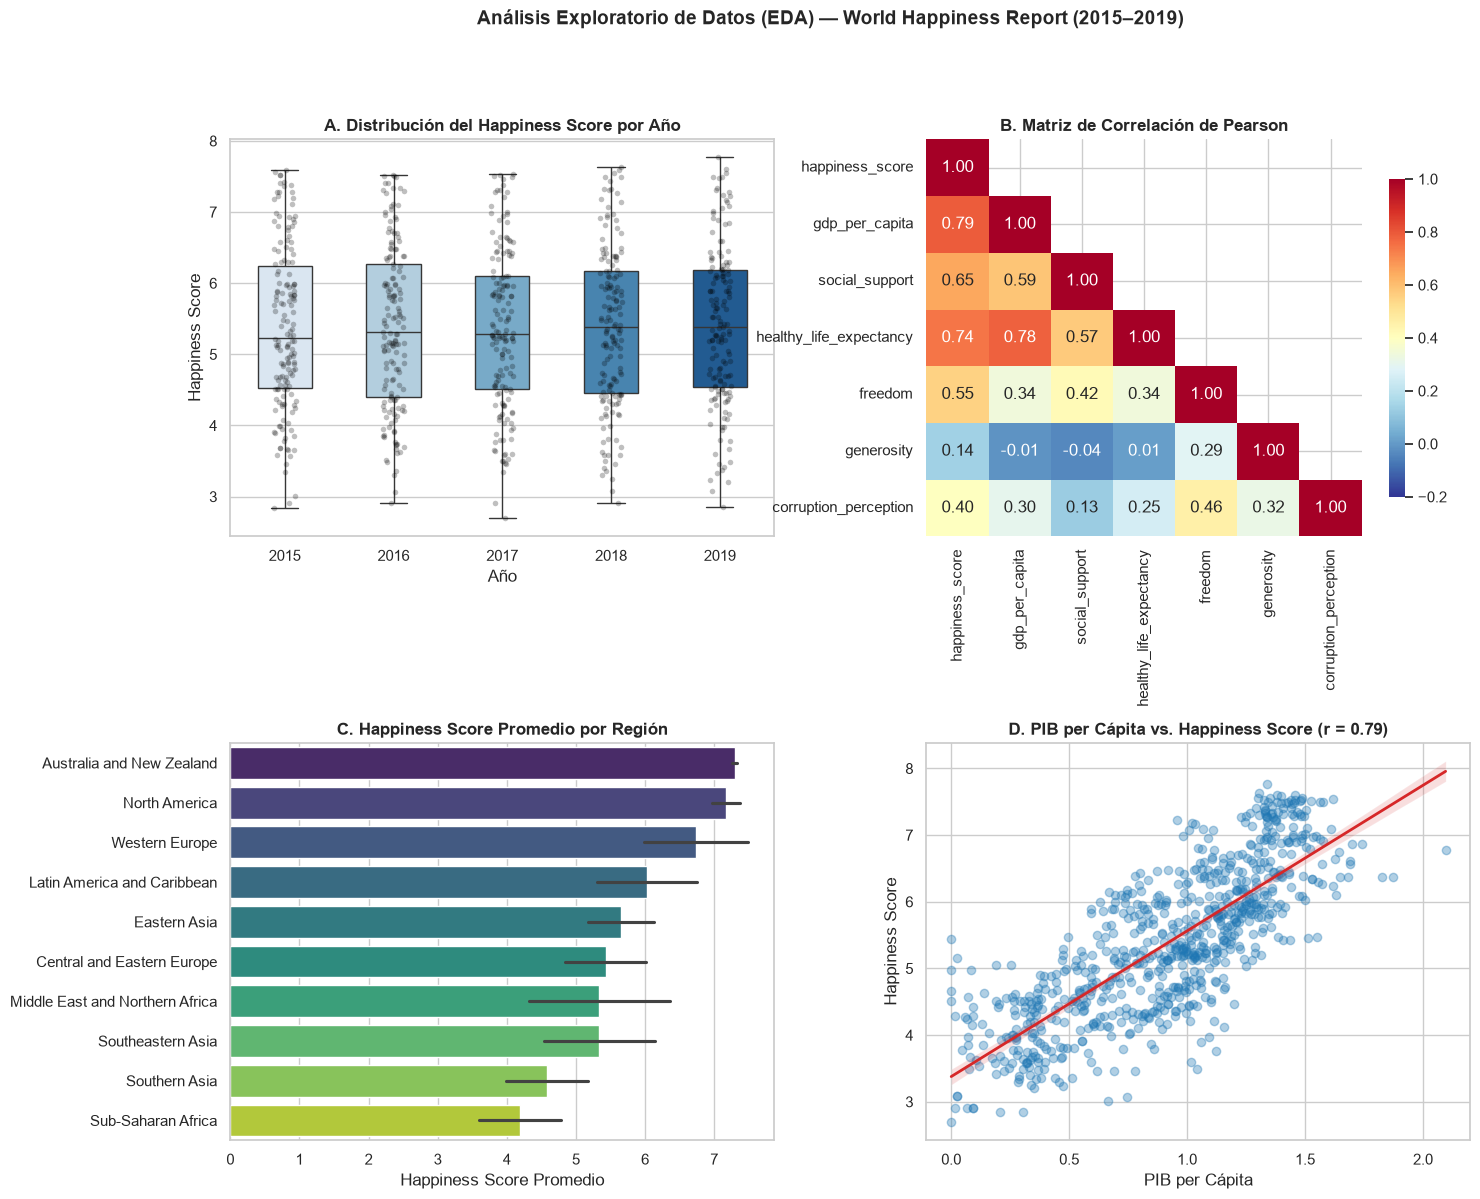

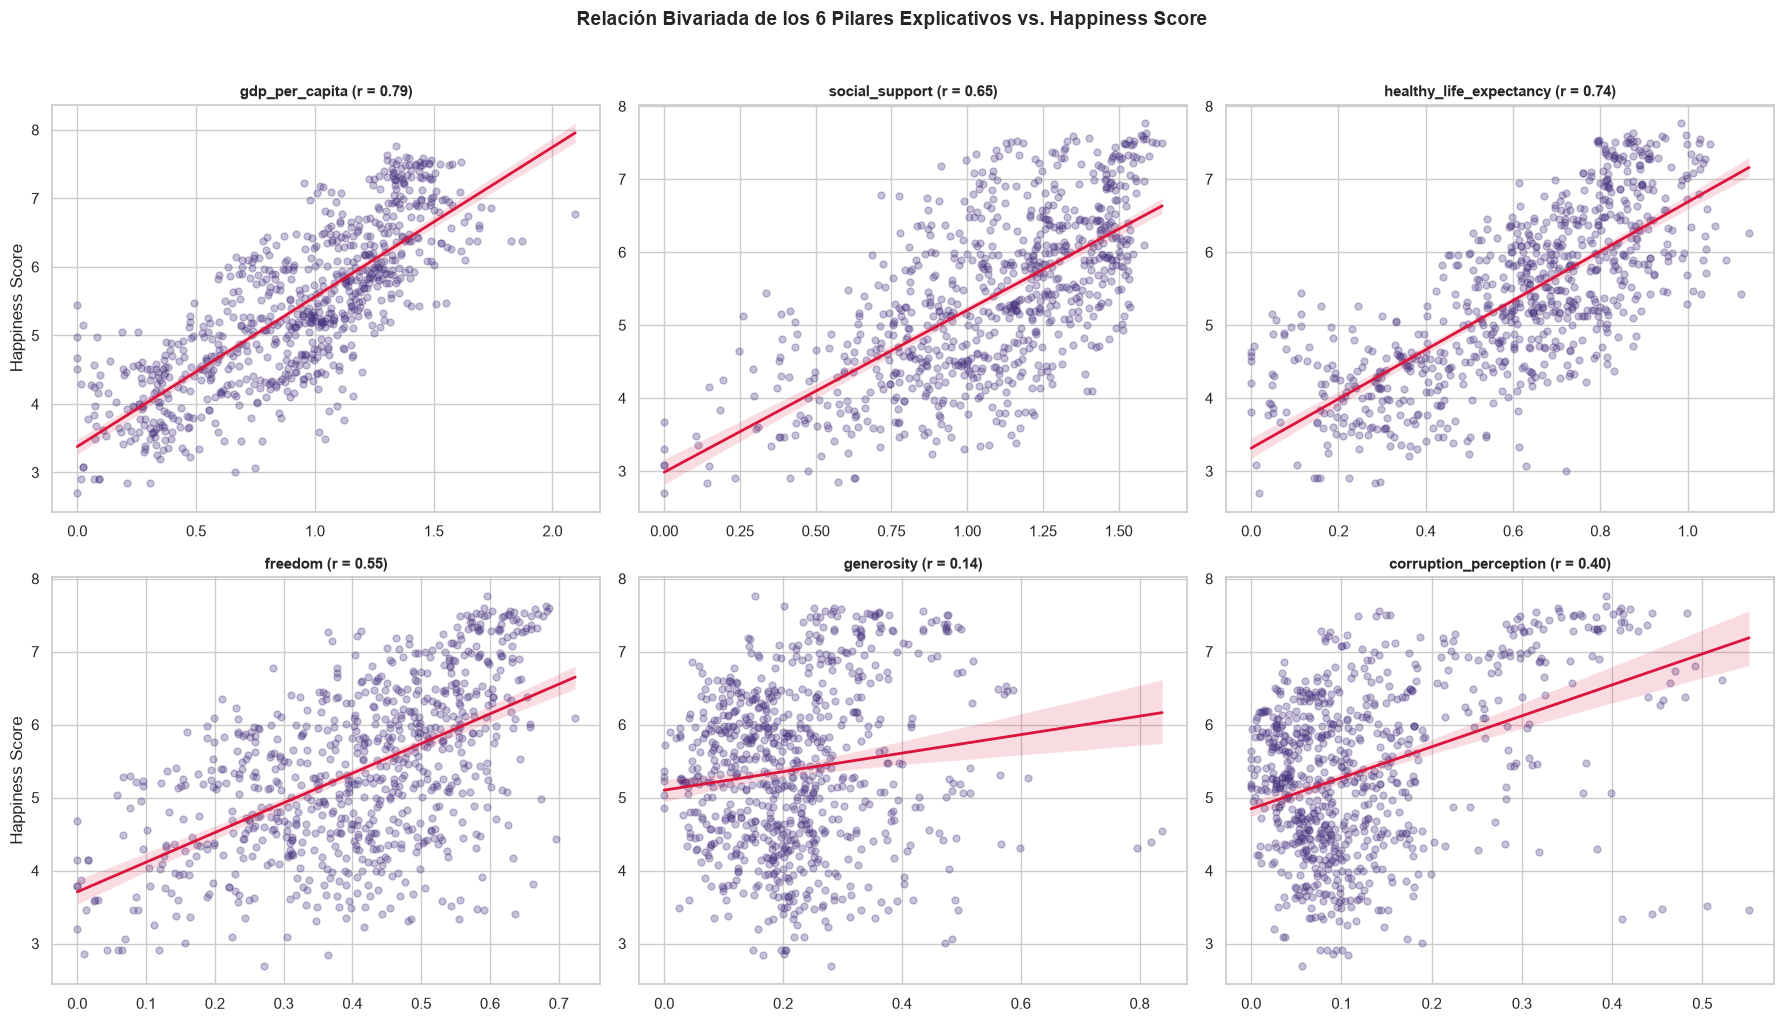

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


FEATURE_COLS = [
    "gdp_per_capita",
    "social_support",
    "healthy_life_expectancy",
    "freedom",
    "generosity",
    "corruption_perception",
]

print("ESTADÍSTICAS DESCRIPTIVAS DEL DATASET INTEGRADO (2015–2019)")
display(df_eda[["happiness_score"] + FEATURE_COLS].describe().T.round(4))

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
plt.subplots_adjust(hspace=0.52, wspace=0.28)

# A. Estabilidad temporal
sns.boxplot(data=df_eda, x="year", y="happiness_score", ax=axes[0, 0], palette="Blues", width=0.5)
sns.stripplot(data=df_eda, x="year", y="happiness_score", ax=axes[0, 0], color="black", alpha=0.25, size=4)
axes[0, 0].set_title("A. Distribución del Happiness Score por Año", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Año")
axes[0, 0].set_ylabel("Happiness Score")

# B. Matriz de correlación
corr_matrix = df_eda[["happiness_score"] + FEATURE_COLS].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdYlBu_r",
    vmin=-0.2, vmax=1.0, center=0.4, ax=axes[0, 1], cbar_kws={"shrink": 0.8}
)
axes[0, 1].set_title("B. Matriz de Correlación de Pearson", fontsize=12, fontweight="bold")

# C. Promedio por región
region_order = df_eda.groupby("region")["happiness_score"].mean().sort_values(ascending=False).index
sns.barplot(
    data=df_eda, y="region", x="happiness_score", order=region_order,
    ax=axes[1, 0], palette="viridis", errorbar="sd"
)
axes[1, 0].set_title("C. Happiness Score Promedio por Región", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Happiness Score Promedio")
axes[1, 0].set_ylabel("")

# D. PIB vs Happiness Score
sns.regplot(
    data=df_eda, x="gdp_per_capita", y="happiness_score", ax=axes[1, 1],
    scatter_kws={"alpha": 0.35, "color": "#1f77b4"}, line_kws={"color": "#d62728", "linewidth": 2}
)
axes[1, 1].set_title("D. PIB per Cápita vs. Happiness Score (r = 0.79)", fontsize=12, fontweight="bold")
axes[1, 1].set_xlabel("PIB per Cápita")
axes[1, 1].set_ylabel("Happiness Score")

plt.suptitle("Análisis Exploratorio de Datos (EDA) — World Happiness Report (2015–2019)", fontsize=14, fontweight="bold", y=0.98)
plt.show()

# Figura 2: Relación bivariada de los 6 factores explicativos
fig, axes_grid = plt.subplots(2, 3, figsize=(18, 10))
axes_grid = axes_grid.flatten()

for idx, feat in enumerate(FEATURE_COLS):
    r_val = df_eda[feat].corr(df_eda["happiness_score"])
    sns.regplot(
        data=df_eda, x=feat, y="happiness_score", ax=axes_grid[idx],
        scatter_kws={"alpha": 0.3, "s": 25}, line_kws={"color": "crimson", "linewidth": 2}
    )
    axes_grid[idx].set_title(f"{feat} (r = {r_val:.2f})", fontsize=11, fontweight="bold")
    axes_grid[idx].set_xlabel("")
    axes_grid[idx].set_ylabel("Happiness Score" if idx % 3 == 0 else "")

plt.suptitle("Relación Bivariada de los 6 Pilares Explicativos vs. Happiness Score", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### Selección de variables relevantes
Con lo observado en las gráficas anteriores, me quedé con **7 variables predictoras** para estimar el `happiness_score`: los seis pilares socioeconómicos (`gdp_per_capita`, `healthy_life_expectancy`, `social_support`, `freedom`, `corruption_perception` y `generosity`) más la variable categórica `region`. Aunque `generosity` tiene una correlación lineal baja ($r = 0.14$)[cite: 11], decidí mantenerla porque los algoritmos basados en árboles pueden aprovechar sus interacciones con otras variables.

Por otro lado, dejé por fuera `happiness_rank` (ya que es simplemente el ordenamiento directo del puntaje objetivo y causaría fuga de información), `country` (demasiadas categorías únicas que llevarían al modelo a memorizar países en vez de aprender patrones) y columnas parciales como `Standard Error`, `Whiskers` o `Dystopia Residual`, que no aparecen en todos los años o forman parte directa de la suma del puntaje final.

### Lo que nos deja el análisis exploratorio (Hallazgos del EDA)
* El puntaje global de felicidad (`happiness_score`) se mantiene muy estable a lo largo de los cinco años, moviéndose alrededor de una media de **5.38** (mediana de **5.32**) en una escala que va de **2.69** a **7.77**[cite: 7, 10].
* Tres factores concentran la mayor relación lineal con la felicidad: el PIB per cápita ($r = 0.79$), la esperanza de vida saludable ($r = 0.74$) y el soporte social ($r = 0.65$)[cite: 10, 11]. Además, estas tres variables están fuertemente correlacionadas entre sí ($r$ entre $0.57$ y $0.78$)[cite: 10].
* Se nota una brecha geográfica marcada: regiones como *Australia and New Zealand*, *North America* y *Western Europe* promedian entre **6.8 y 7.3** puntos, mientras que *Sub-Saharan Africa* y *Southern Asia* se ubican en la franja más baja, entre **4.2 y 4.6**[cite: 10].

## 3. Entrenamiento del modelo de regresión (Model Training)

Definida la variable objetivo (`happiness_score`) y las 7 predictoras, dividí el conjunto de datos en **80% para entrenamiento (625 filas)** y **20% para prueba (157 filas)** antes de aplicar cualquier transformación. Hacer esta partición al principio evita que la mediana de imputación o las medias del escalado se calculen usando información del conjunto de prueba (*data leakage*).

Para mantener el preprocesamiento limpio y reproducible, encapsulé las transformaciones dentro de un `ColumnTransformer` y un `Pipeline` de Scikit-Learn:
* A las **6 variables numéricas** les apliqué imputación por mediana (`SimpleImputer`) seguida de estandarización (`StandardScaler`).
* A la variable **`region`** le apliqué imputación por moda y codificación *One-Hot* (`handle_unknown='ignore'`) para que el pipeline no falle si en el futuro entra una región no vista.

Como punto de partida entrené una **Regresión Lineal** sencilla, dado que el índice original tiene una base aditiva. Luego la comparé mediante validación cruzada de 5 particiones (*5-fold CV*) contra **Ridge Regression** (para ver si la penalización L2 ayudaba con la colinealidad entre PIB y salud) y contra dos ensambles no lineales: **Random Forest** y **Gradient Boosting Regressor**, buscando capturar interacciones entre el contexto regional y los indicadores económicos. Al finalizar, guardé el pipeline ganador en disco con `joblib` (`.pkl`).

In [14]:
import joblib
from datetime import datetime, timezone
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
import os

# 1. Definir la variable objetivo (y) y los predictoras (X)
NUM_FEATURES = [
    "gdp_per_capita",
    "social_support",
    "healthy_life_expectancy",
    "freedom",
    "generosity",
    "corruption_perception",
]
CAT_FEATURES = ["region"]
ALL_FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET_COL = "happiness_score"

X = df_harmonized[ALL_FEATURES].copy()
y = df_harmonized[TARGET_COL].copy()

# 2. Separar Train / Test antes de preprocesar para evitar Data-Leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"X_train: {X_train.shape} (nulos: {X_train.isna().sum().sum()}) | X_test: {X_test.shape} (nulos: {X_test.isna().sum().sum()})")

# 3. Estrategia de preprocesamiento encapsulada en ColumnTransformer
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUM_FEATURES),
        ("cat", categorical_transformer, CAT_FEATURES),
    ],
    remainder="drop",
)

# 4. Entrenamiento y comparación mediante Validación Cruzada
models = {
    "Linear Regression (Baseline)": LinearRegression(),
    "Ridge Regression (L2)": Ridge(alpha=1.0, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200, max_depth=10, min_samples_leaf=2, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42
    ),
}

trained_pipelines = {}
cv_rows = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", estimator),
    ])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    cv_rmse = -cross_val_score(pipe, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")

    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe

    cv_rows.append({
        "Modelo": name,
        "CV_R2_Mean": cv_r2.mean(),
        "CV_R2_Std": cv_r2.std(),
        "CV_RMSE_Mean": cv_rmse.mean(),
    })

df_cv = pd.DataFrame(cv_rows).sort_values(by="CV_R2_Mean", ascending=False)
print("\nResultados de Validación Cruzada (5-Fold sobre X_train):")
display(df_cv.round(4))

best_model_name = df_cv.iloc[0]["Modelo"]
best_pipeline = trained_pipelines[best_model_name]
print(f"\nModelo seleccionado: {best_model_name}")

# Serialización del Artifact Store (.pkl + metadata JSON)
os.makedirs("artifacts", exist_ok=True)
MODEL_PATH = "artifacts/happiness_predictor_pipeline.pkl"
METADATA_PATH = "artifacts/model_metadata.json"

joblib.dump(best_pipeline, MODEL_PATH)
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump({
        "model_name": best_model_name,
        "trained_at_utc": datetime.now(timezone.utc).isoformat(),
        "features": ALL_FEATURES,
        "target": TARGET_COL,
    }, f, indent=2)

print(f"Modelo y preprocesador serializados en '{MODEL_PATH}'")

X_train: (625, 7) (nulos: 1) | X_test: (157, 7) (nulos: 0)

Resultados de Validación Cruzada (5-Fold sobre X_train):


,Modelo,CV_R2_Mean,CV_R2_Std,CV_RMSE_Mean
3,Gradient Boosting Regressor,0.8349,0.0131,0.4553
2,Random Forest Regressor,0.8343,0.0147,0.4560
0,Linear Regression (Baseline),0.8018,0.0193,0.4992
1,Ridge Regression (L2),0.8009,0.0194,0.5002



Modelo seleccionado: Gradient Boosting Regressor
Modelo y preprocesador serializados en 'artifacts/happiness_predictor_pipeline.pkl'


## 4. Evaluación del modelo y resultados (Model Evaluation)

Una vez entrenados los modelos, evalué qué tan bien funcionan sobre los 157 registros reservados en `X_test`, comparando los puntajes reales contra los que predijo cada algoritmo. Para tener una lectura completa del error, calculé cuatro métricas:

* **MAE:** el error promedio en puntos directos de felicidad.
* **MSE y RMSE:** métricas que penalizan más fuerte cuando el modelo se equivoca por mucho en un país puntual.
* **R² y R² ajustado:** qué porcentaje de la variación total del puntaje logra explicar el modelo, ajustando también por la cantidad de columnas que quedaron después del *One-Hot Encoding*.

Con los gráficos de abajo revisé tres cosas clave: qué tanto se acercan las predicciones a los valores reales, si los errores se reparten de forma pareja sin sesgos y cuáles fueron las variables que más pesaron al momento de predecir.

EVALUACIÓN DE MODELOS EN CONJUNTO DE PRUEBA (X_TEST - 157 REGISTROS)


,Modelo,MAE,MSE,RMSE,R2,R2_Ajustado
3,Gradient Boosting Regressor,0.3469,0.1934,0.4398,0.8478,0.8316
2,Random Forest Regressor,0.3389,0.1999,0.4471,0.8427,0.8260
0,Linear Regression (Baseline),0.3980,0.2639,0.5137,0.7924,0.7703
1,Ridge Regression (L2),0.3979,0.2647,0.5145,0.7917,0.7696



Muestra de comparación Real vs. Predicho en Test (Top 10 primeros registros):


,Country,Year,Actual_Score,Predicted_Score,Residual (y - ŷ),Abs_Error
596,Puerto Rico,2016,7.039,6.5032,0.5358,0.5358
588,Chad,2015,3.667,4.3870,-0.7200,0.7200
208,Congo (Brazzaville),2018,4.559,4.3451,0.2139,0.2139
291,Poland,2015,5.791,5.8497,-0.0587,0.0587
174,United States,2018,6.886,6.9859,-0.0999,0.0999
292,Russia,2015,5.716,5.1414,0.5746,0.5746
711,Turkey,2018,5.483,5.4372,0.0458,0.0458
210,Kenya,2018,4.410,4.0840,0.3260,0.3260
266,Zimbabwe,2019,3.663,4.2962,-0.6332,0.6332
331,New Zealand,2016,7.334,7.1568,0.1772,0.1772



Interpretación de Métricas (Gradient Boosting Regressor):
   • R² = 0.8478 (R² Ajustado = 0.8316): Explica el 84.78% de la varianza del Happiness Score en datos inéditos.
   • MAE = 0.3469: En promedio, la predicción se desvía ±0.347 puntos respecto al valor real.
   • MSE = 0.1934 | RMSE = 0.4398: Desviación típica de los errores penalizando valores extremos.


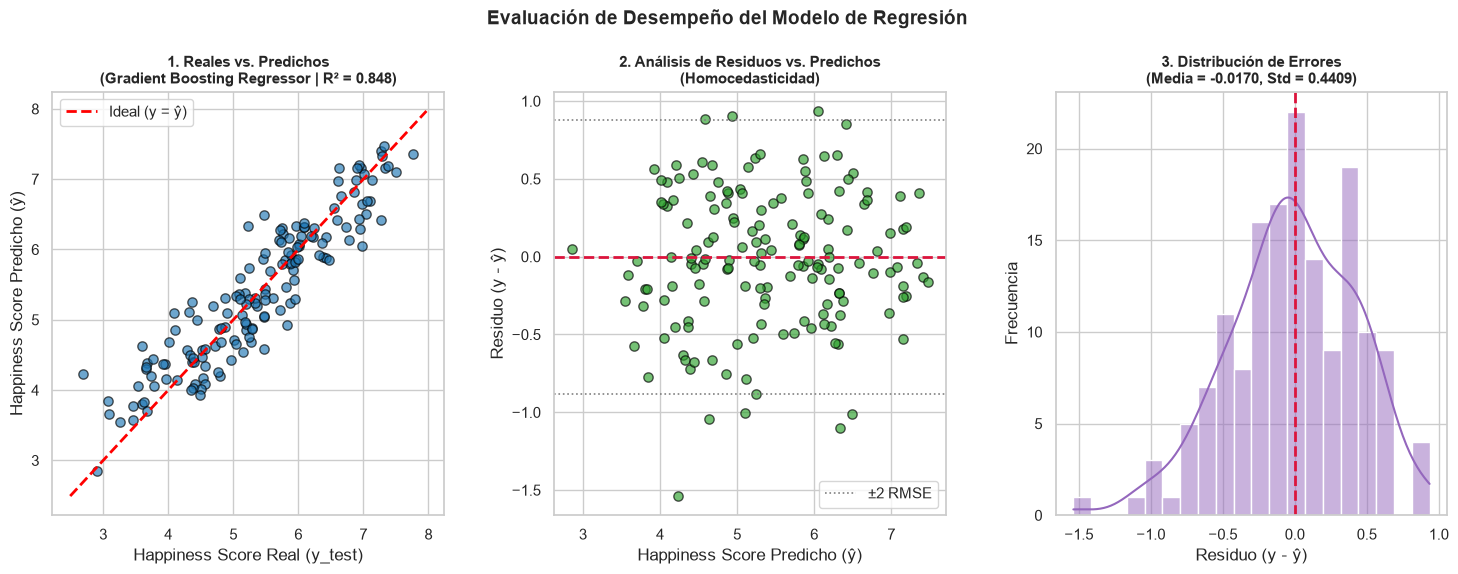

C:\Users\Leidy\AppData\Local\Temp\ipykernel_8672\4198177965.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp, x="Importance", y="Feature", palette="magma")


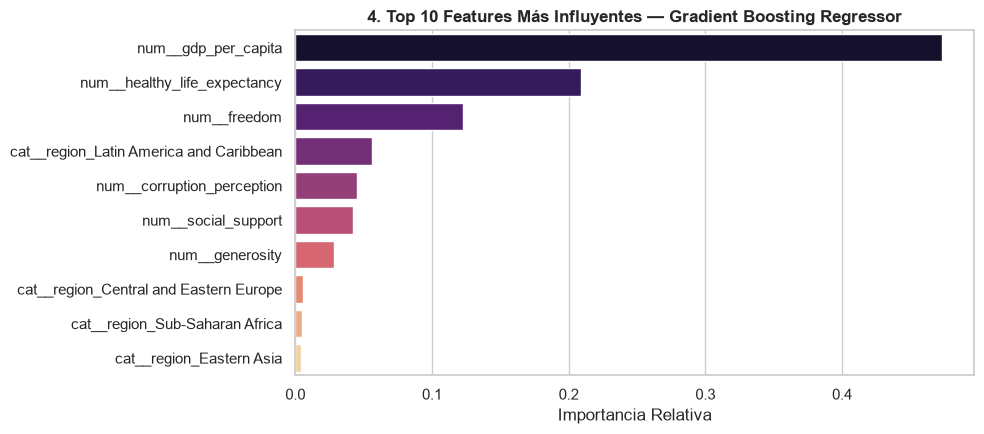

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

n_test = len(y_test)
p_transformed = best_pipeline.named_steps["preprocessor"].transform(X_test).shape[1]

eval_rows = []
for name, pipe in trained_pipelines.items():
    preds = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, preds)
    adj_r2 = 1 - ((1 - r2) * (n_test - 1)) / (n_test - p_transformed - 1)
    eval_rows.append({
        "Modelo": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "R2_Ajustado": adj_r2,
    })

df_eval = pd.DataFrame(eval_rows).sort_values(by="R2", ascending=False)
print("EVALUACIÓN DE MODELOS EN CONJUNTO DE PRUEBA (X_TEST - 157 REGISTROS)")
display(df_eval.round(4))

y_pred_best = best_pipeline.predict(X_test)
residuals = y_test - y_pred_best

df_comparison = pd.DataFrame({
    "Country": df_harmonized.loc[X_test.index, "country"],
    "Year": df_harmonized.loc[X_test.index, "year"],
    "Actual_Score": y_test.values,
    "Predicted_Score": y_pred_best,
    "Residual (y - ŷ)": residuals.values,
    "Abs_Error": np.abs(residuals.values),
})
print("\nMuestra de comparación Real vs. Predicho en Test (Top 10 primeros registros):")
display(df_comparison.head(10).round(4))

best_row = df_eval.iloc[0]
print(f"\nInterpretación de Métricas ({best_model_name}):")
print(f"   • R² = {best_row['R2']:.4f} (R² Ajustado = {best_row['R2_Ajustado']:.4f}): Explica el {best_row['R2']*100:.2f}% de la varianza del Happiness Score en datos inéditos.")
print(f"   • MAE = {best_row['MAE']:.4f}: En promedio, la predicción se desvía ±{best_row['MAE']:.3f} puntos respecto al valor real.")
print(f"   • MSE = {best_row['MSE']:.4f} | RMSE = {best_row['RMSE']:.4f}: Desviación típica de los errores penalizando valores extremos.")


fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
plt.subplots_adjust(wspace=0.28)

# 1. Reales vs Predichos
axes[0].scatter(y_test, y_pred_best, alpha=0.65, color="#1f77b4", edgecolor="k", s=45)
lims = [min(y_test.min(), y_pred_best.min()) - 0.2, max(y_test.max(), y_pred_best.max()) + 0.2]
axes[0].plot(lims, lims, "r--", lw=2, label="Ideal (y = ŷ)")
axes[0].set_title(f"1. Reales vs. Predichos\n({best_model_name} | R² = {best_row['R2']:.3f})", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Happiness Score Real (y_test)")
axes[0].set_ylabel("Happiness Score Predicho (ŷ)")
axes[0].legend()

# 2. Residuos vs Predichos
axes[1].scatter(y_pred_best, residuals, alpha=0.65, color="#2ca02c", edgecolor="k", s=45)
axes[1].axhline(0, color="crimson", linestyle="--", lw=2)
axes[1].axhline(2 * best_row["RMSE"], color="gray", linestyle=":", lw=1.2, label="±2 RMSE")
axes[1].axhline(-2 * best_row["RMSE"], color="gray", linestyle=":", lw=1.2)
axes[1].set_title("2. Análisis de Residuos vs. Predichos\n(Homocedasticidad)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Happiness Score Predicho (ŷ)")
axes[1].set_ylabel("Residuo (y - ŷ)")
axes[1].legend()

# 3. Histograma de Residuos
sns.histplot(residuals, kde=True, bins=20, ax=axes[2], color="#9467bd")
axes[2].axvline(0, color="crimson", linestyle="--", lw=2)
axes[2].set_title(f"3. Distribución de Errores\n(Media = {residuals.mean():.4f}, Std = {residuals.std():.4f})", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Residuo (y - ŷ)")
axes[2].set_ylabel("Frecuencia")

plt.suptitle("Evaluación de Desempeño del Modelo de Regresión", fontsize=14, fontweight="bold", y=1.03)
plt.show()

# 4. Importancia de variables / Coeficientes
prep_fitted = best_pipeline.named_steps["preprocessor"]
reg_fitted = best_pipeline.named_steps["regressor"]
feat_names = prep_fitted.get_feature_names_out()

if hasattr(reg_fitted, "feature_importances_"):
    imp_vals = reg_fitted.feature_importances_
    imp_label = "Importancia Relativa"
else:
    imp_vals = np.abs(reg_fitted.coef_)
    imp_label = "Magnitud Absoluta del Coeficiente (|β|)"

df_imp = pd.DataFrame({"Feature": feat_names, "Importance": imp_vals}).sort_values(by="Importance", ascending=False).head(10)
plt.figure(figsize=(10, 4.5))
sns.barplot(data=df_imp, x="Importance", y="Feature", palette="magma")
plt.title(f"4. Top 10 Features Más Influyentes — {best_model_name}", fontsize=12, fontweight="bold")
plt.xlabel(imp_label)
plt.ylabel("")
plt.tight_layout()
plt.show()

### Discusión de resultados y posibles mejoras
En el conjunto de prueba, **Gradient Boosting Regressor** obtuvo el mejor rendimiento con un **R² de 0.8478** (R² ajustado de **0.8316**), un **RMSE de 0.4398** y un **MAE de 0.3469**. Frente a la Regresión Lineal base (R² de 0.7924 y RMSE de 0.5137), el ensamble logra explicar **5.5 puntos porcentuales más de varianza**, confirmando que existen relaciones no lineales relevantes entre los indicadores socioeconómicos y la región. Además, la cercanía entre el R² de validación cruzada (`0.8349`) y el de prueba (`0.8478`) indica que el modelo generaliza bien y no cayó en sobreajuste.

Al revisar los gráficos de diagnóstico, los residuos se distribuyen alrededor de cero (media de -0.017 y desviación estándar de 0.441) sin mostrar patrones de embudo claros. Los casos con mayor desviación puntual (como Chad o Puerto Rico) se explican porque el *World Happiness Report* original contempla un componente no observable llamado *Dystopia + Residual* que recoge factores culturales o coyunturales propios de cada país y que no está presente en las 6 variables base. En cuanto a importancia de variables, el peso recae principalmente en `gdp_per_capita` (~47%), `healthy_life_expectancy` (~21%) y `freedom` (~12%), seguidos por el ajuste positivo asociado a `Latin America and Caribbean`.

**¿Qué se podría mejorar en una siguiente iteración?**
1. **Validación agrupada por país (`GroupKFold`):** Separar entrenamiento y prueba asegurando que todos los años de un mismo país queden en un solo lado, para medir qué tan bien predice el modelo sobre países totalmente desconocidos.
2. **Búsqueda de hiperparámetros:** Ajustar de forma sistemática (`RandomizedSearchCV`) parámetros como `learning_rate`, `max_depth` y `subsample` para intentar bajar el RMSE por debajo de 0.40.
3. **Cruzar fuentes externas:** Añadir variables macroeconómicas como el coeficiente de Gini (desigualdad) o tasas de desempleo para reducir la parte del puntaje que hoy queda como residuo.

In [16]:
import sqlite3
import uuid

# 1. Cargar artefacto serializado (.pkl) desde el Artifact Store
loaded_pipeline = joblib.load(MODEL_PATH)
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    loaded_meta = json.load(f)

# 2. Simular micro-batch de eventos consumidos desde Kafka (incluyendo el registro con NaN para probar resiliencia)
batch_indices = list(X_test.index[:24])
if 176 in df_harmonized.index and 176 not in batch_indices:
    batch_indices.append(176)

stream_records = []
for idx in batch_indices:
    meta_msg = metadata[idx]
    row = df_harmonized.loc[idx]
    stream_records.append({
        "kafka_topic": meta_msg["topic"],
        "kafka_partition": meta_msg["partition"],
        "kafka_offset": meta_msg["offset"],
        "kafka_key": meta_msg["key"],
        "year": int(row["year"]),
        "country": row["country"],
        "region": row["region"],
        "gdp_per_capita": row["gdp_per_capita"],
        "social_support": row["social_support"],
        "healthy_life_expectancy": row["healthy_life_expectancy"],
        "freedom": row["freedom"],
        "generosity": row["generosity"],
        "corruption_perception": row["corruption_perception"],
        "actual_happiness_score": float(row["happiness_score"]),
    })

df_stream_batch = pd.DataFrame(stream_records)
df_stream_batch["predicted_happiness_score"] = loaded_pipeline.predict(df_stream_batch[loaded_meta["features"]])
df_stream_batch["absolute_error"] = np.abs(df_stream_batch["actual_happiness_score"] - df_stream_batch["predicted_happiness_score"])
df_stream_batch["prediction_id"] = [str(uuid.uuid4()) for _ in range(len(df_stream_batch))]
df_stream_batch["model_version"] = loaded_meta["model_name"]
df_stream_batch["processed_at_utc"] = datetime.now(timezone.utc).isoformat()

# 3. Guardar predicciones en SQLite
DB_PATH = "warehouse_happiness.db"
conn = sqlite3.connect(DB_PATH)
df_stream_batch.to_sql("happiness_predictions", conn, if_exists="replace", index=False)

# 4. Consulta SQL de verificación
df_verified = pd.read_sql_query("""
    SELECT kafka_partition, kafka_offset, year, country,
           ROUND(actual_happiness_score, 3) AS real_score,
           ROUND(predicted_happiness_score, 3) AS pred_score,
           ROUND(absolute_error, 3) AS abs_error,
           model_version
    FROM happiness_predictions
    ORDER BY abs_error ASC
    LIMIT 10;
""", conn)
conn.close()

print(f"Predicciones persistidas exitosamente en '{DB_PATH}' (tabla: happiness_predictions)")
display(df_verified)

Predicciones persistidas exitosamente en 'warehouse_happiness.db' (tabla: happiness_predictions)


,kafka_partition,kafka_offset,year,country,real_score,pred_score,abs_error,model_version
0,1,110,2016,Armenia,4.360,4.405,0.045,Gradient Boosting Regressor
1,0,158,2018,Turkey,5.483,5.437,0.046,Gradient Boosting Regressor
2,2,245,2019,Thailand,6.008,6.054,0.046,Gradient Boosting Regressor
3,1,156,2017,Zambia,4.514,4.563,0.049,Gradient Boosting Regressor
4,2,22,2015,Poland,5.791,5.850,0.059,Gradient Boosting Regressor
5,1,79,2016,Malaysia,6.005,6.083,0.078,Gradient Boosting Regressor
6,1,175,2018,United States,6.886,6.986,0.100,Gradient Boosting Regressor
7,1,193,2018,Belarus,5.483,5.368,0.115,Gradient Boosting Regressor
8,0,185,2019,Canada,7.278,7.406,0.128,Gradient Boosting Regressor
9,1,197,2018,Greece,5.358,5.194,0.164,Gradient Boosting Regressor


## 5. Flujo de inferencia y almacenamiento en base de datos

Para cerrar el ciclo completo de la arquitectura vista en clase, simulé la llegada de un lote de registros provenientes del stream de Kafka (`etl.records`), incluyendo intencionalmente el registro de Emiratos Árabes Unidos con un valor faltante para comprobar que el pipeline serializado lo procesa sin problemas.

Cargué el archivo `happiness_predictor_pipeline.pkl` desde la carpeta `artifacts`, generé las predicciones y crucé cada resultado con sus metadatos originales de Kafka (`kafka_partition`, `kafka_offset` y `kafka_key`) para no perder la trazabilidad del evento. Finalmente, guardé toda la tabla enriquecida en una base de datos SQLite local (`warehouse_happiness.db`, tabla `happiness_predictions`) y validé mediante una consulta SQL que los registros quedaran almacenados correctamente.